In [221]:
!pip install -qq pandas numpy matplotlib seaborn
import pandas as pd 
import numpy as np 
from matplotlib import pyplot as plt 
import seaborn as sns 
%matplotlib inline


In [222]:
# !curl -O https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

In [223]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
dff = pd.read_csv(url)
dff.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [224]:
df = dff.loc[:, ['engine_displacement', 'horsepower', 'vehicle_weight','model_year', 'fuel_efficiency_mpg']]
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


Text(0, 0.5, 'Count')

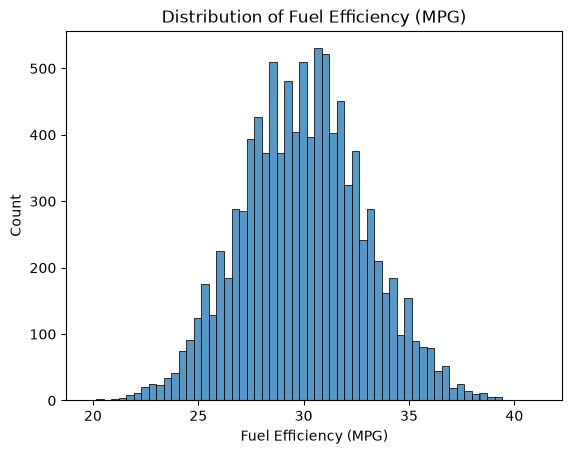

In [241]:
sns.histplot(dff.fuel_efficiency_mpg)
plt.title('Distribution of Fuel Efficiency (MPG)')
plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Count')
# normal distribution orGaussian has bell-shaped curve, which is symmetric with center as peak

Text(0, 0.5, 'Count')

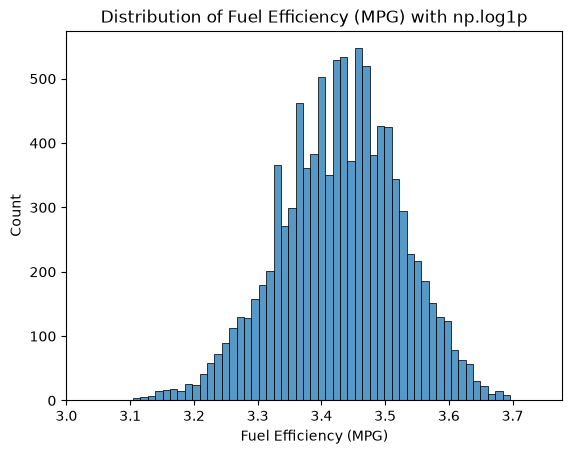

In [242]:
log_fuel_efficiency = np.log1p(df.fuel_efficiency_mpg) 
sns.histplot(log_fuel_efficiency)
plt.title('Distribution of Fuel Efficiency (MPG) with np.log1p')
plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Count')

In [227]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [228]:
df['horsepower'].describe()

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64

In [229]:
df['horsepower'].quantile(0.5)

254.0

In [230]:
df_42 = df.copy()

In [231]:
n = len(df_42) 
n_val = int(0.2 * n)
n_test = int(0.2 * n) 
n_train = n - (n_val + n_test)

print(f"Validation size 20%: {n_val}")
print(f"Test size 20%: {n_test}")
print(f"Validation size 20%: {n_train}")
np.random.seed(42) 
idx = np.arange(n) 
np.random.shuffle(idx) 
df_shuffled_42 = df_42.iloc[idx] 
df_train = df_shuffled_42.iloc[:n_train].copy() 
df_val = df_shuffled_42.iloc[n_train:n_train+n_val].copy() 
df_test = df_shuffled_42.iloc[n_train+n_val:].copy() 

Validation size 20%: 2000
Test size 20%: 2000
Validation size 20%: 6000


In [232]:
def rmse(y, y_pred):
    error = y - y_pred
    mse = (error ** 2).mean()
    return np.sqrt(mse)

def linear_regression(X, y): 
 ones = np.ones(X.shape[0]) 
 X = np.column_stack([ones, X]) 
 XTX = X.T.dot(X) 
 XTX_inv = np.linalg.inv(XTX) 
 w = XTX_inv.dot(X.T).dot(y) 
 return w[0], w[1:] 

In [233]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv @ X.T @ y
    return w[0], w[1:]

In [234]:
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values

In [235]:
# Define the exact features to use minus fuel_efficiency_mpg column
features = [c for c in df_train.columns if c != 'fuel_efficiency_mpg']

# Select ONLY those features for both Train and Validation
X_tr_0 = df_train[features].copy()
X_v_0 = df_val[features].copy()

# Fill in horsepower missing values
X_tr_0['horsepower'] = X_tr_0['horsepower'].fillna(0)
X_v_0['horsepower'] = X_v_0['horsepower'].fillna(0)

# Train and predict rmse score
w0, w = train_linear_regression(X_tr_0.values, y_train)
y_pred_0 = w0 + X_v_0.values @ w
score_0 = round(rmse(y_val, y_pred_0), 3)

In [236]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X
    reg = r * np.identity(XTX.shape[0])
    # Note: Option to not regularize bias term w0: reg[0, 0] = 
    # =r Only feature coefficients ($w_1, w_2, \dots$) are penalized.
    # = 0 Both feature coefficients and the intercept $w_0$ are penalized
    reg[0, 0] = 0  
    XTX_inv = np.linalg.inv(XTX + reg)
    w = XTX_inv @ X.T @ y
    return w[0], w[1:]

In [237]:
X_tr_m = df_train[features].copy()
X_v_m = df_val[features].copy()

# Calculate mean from TRAIN set ONLY
mean_hp = X_tr_m['horsepower'].mean()

# Fill in missing values with train mean
X_tr_m['horsepower'] = X_tr_m['horsepower'].fillna(mean_hp)
X_v_m['horsepower'] = X_v_m['horsepower'].fillna(mean_hp)

# Train and predict
w0, w = train_linear_regression(X_tr_m.values, y_train)
y_pred_m = w0 + X_v_m.values @ w
score_mean = round(rmse(y_val, y_pred_m), 3)

print(f"RMSE (Fill with 0):    {score_0}")
print(f"RMSE (Fill with Mean): {score_mean}")

RMSE (Fill with 0):    2.205
RMSE (Fill with Mean): 2.202


In [238]:
X_train = df_train[features].copy()
X_val = df_val[features].copy()

X_train = X_train.fillna(0).values
X_val = X_val.fillna(0).values

# Regularization strength r array
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

results = {}
for r in r_values:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val @ w
    score = round(rmse(y_val, y_pred), 4)
    results[r] = score
    print(f"r = {r:<5} | RMSE = {score}")

# select the best r (minimum RMSE)
best_r = min(results, key=results.get)
print(f"\nBest r: {best_r} with RMSE = {results[best_r]}")

r = 0     | RMSE = 2.2053
r = 0.01  | RMSE = 2.2053
r = 0.1   | RMSE = 2.2053
r = 1     | RMSE = 2.2053
r = 5     | RMSE = 2.2053
r = 10    | RMSE = 2.2053
r = 100   | RMSE = 2.2053

Best r: 0 with RMSE = 2.2053


In [239]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []
df_seeds = df.copy()
n = len(df_seeds)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

features = [c for c in df.columns if c != 'fuel_efficiency_mpg']

for seed in seeds:
    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)
    # Split data (60% Train / 20% Val / 20% Test)
    df_shuffled = df.iloc[idx].reset_index(drop=True)
    df_train = df_shuffled.iloc[:n_train].copy()
    df_val = df_shuffled.iloc[n_train:n_train + n_val].copy()
    # 3. Extract target
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values
    
    # Extract features & impute NAs with 0
    X_train = df_train[features].fillna(0).values
    X_val = df_val[features].fillna(0).values
    
    # Train model without regularization
    w0,w = linear_regression(X_train, y_train)
    # w0, w = train_linear_regression(X_train, y_train)
    
    # Predict on validation set and calculate RMSE
    y_pred = w0 + X_val @ w
    score = rmse(y_val, y_pred)
    scores.append(score)

# Calcualte standard deviation across all seed scores
std_score = np.std(scores)
std_rounded = round(std_score, 3)

print("RMSE scores per seed:", [round(s, 3) for s in scores])
print(f"Standard deviation of scores: {std_rounded}")
# Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. 
# If it's high, the values are different. If standard deviation of scores is low, then our model is stable.

RMSE scores per seed: [2.239, 2.202, 2.163, 2.204, 2.202, 2.246, 2.27, 2.191, 2.217, 2.207]
Standard deviation of scores: 0.029


In [240]:
df_seed_nine = df.copy()
# Seed and define split sizes (60% Train, 20% Val, 20% Test
seed = 9
n = len(df_seed_nine)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)
idx = np.arange(n)
np.random.seed(seed)
np.random.shuffle(idx)

# Split into train, validate, and test subsets
df_shuffled_nine = df.iloc[idx].reset_index(drop=True)

df_train = df_shuffled_nine.iloc[:n_train].copy()
df_val = df_shuffled_nine.iloc[n_train:n_train + n_val].copy()
df_test = df_shuffled_nine.iloc[n_train + n_val:].copy()

# Combine train and validation sets
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

# Extract target array
y_full_train = df_full_train['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

# extract feature matrices and fill missing values with 0
features = [c for c in df.columns if c != 'fuel_efficiency_mpg']
X_full_train = df_full_train[features].fillna(0).values
X_test = df_test[features].fillna(0).values

# Train model on combined train+val with r=0.001
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

# Predict and evaluate on the test dataset and get rmse
y_pred_test = w0 + X_test @ w
test_rmse = round(rmse(y_test, y_pred_test), 3)  # or round(test_rmse, 3) depending on course requirement
print(f"Test RMSE: {test_rmse}")

Test RMSE: 2.236
